# Binning and Binarization

In [1]:
import pandas as pd 
import numpy as np 


In [7]:
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer 
from sklearn.compose import ColumnTransformer

In [8]:
df= pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

In [9]:
df.dropna(inplace=True)

In [11]:
df.shape

(714, 3)

In [12]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [13]:
X = df.iloc[:,1:]
y=df.iloc[:,0]

In [14]:
X_train,X_test,y_train,y_test =train_test_split(X,y,test_size=0.2,random_state=42)

In [15]:
X_train.head(2)

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542


In [16]:
clf = DecisionTreeClassifier()

In [17]:
clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)

In [18]:
accuracy_score(y_test,y_pred)

0.6223776223776224

In [20]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.6218896713615024)

In [21]:
kbin_age = KBinsDiscretizer(n_bins=10,encode='ordinal',strategy='quantile')
kbin_fare = KBinsDiscretizer(n_bins=10,encode='ordinal',strategy='quantile')

In [22]:
trf = ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_age,[1])
])

In [23]:
X_train_trf =trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [25]:
trf.named_transformers_

{'first': KBinsDiscretizer(encode='ordinal', n_bins=10),
 'second': KBinsDiscretizer(encode='ordinal', n_bins=10)}

In [24]:
trf.named_transformers_['first'].n_bins_

array([10])

In [26]:
trf.named_transformers_['first'].bin_edges_

array([array([ 0.42, 14.  , 19.  , 22.  , 25.  , 28.5 , 32.  , 36.  , 42.  ,
              50.  , 80.  ])                                                ],
      dtype=object)

In [27]:
output = pd.DataFrame({
    'age':X_train['Age'],
    'age_trf':X_train_trf[:,0],
    'fare':X_train['Fare'],
    'fare_trf':X_train_trf[:,1]
})

In [29]:
output['age_labels'] = pd.cut(x=X_train['Age'],
                             bins=trf.named_transformers_['first'].bin_edges_[0].tolist())
output['fare_labels'] = pd.cut(x=X_train['Fare'],
                              bins=trf.named_transformers_['second'].bin_edges_[0].tolist())

In [30]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
332,38.0,7.0,153.4625,9.0,"(36.0, 42.0]","(82.171, 512.329]"
558,39.0,7.0,79.6500,8.0,"(36.0, 42.0]","(51.479, 82.171]"
16,2.0,0.0,29.1250,7.0,"(0.42, 14.0]","(26.0, 29.125]"
327,36.0,7.0,13.0000,4.0,"(32.0, 36.0]","(9.225, 13.0]"
227,20.5,2.0,7.2500,0.0,"(19.0, 22.0]","(0.0, 7.75]"


In [33]:
clf = DecisionTreeClassifier()
clf.fit(X_train_trf,y_train)
y_pred2 = clf.predict(X_test_trf)

In [34]:
accuracy_score(y_test,y_pred2)

0.6223776223776224

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

def discretize(bins, strategy):
    # Initialize the discretizers
    kbin_age = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins, encode='ordinal', strategy=strategy)
    
    # Apply to specific column indices ([0] for Age, [1] for Fare)
    trf = ColumnTransformer([
        ('first', kbin_age, [0]),
        ('second', kbin_fare, [1])
    ])
    
    # Transform the dataset
    X_trf = trf.fit_transform(X)
    
    # ⚠️ FIX: Changed 'X' to 'X_trf' to evaluate the transformed data, not the raw data
    accuracy = np.mean(cross_val_score(DecisionTreeClassifier(), X_trf, y, cv=10, scoring='accuracy'))
    print(f"Mean Accuracy: {accuracy:.4f}")
    
    # Plotting Before vs After
    plt.figure(figsize=(14, 4))
    
    # Before Discretization
    plt.subplot(121)
    plt.hist(X['Age'], bins=bins, edgecolor='black')
    plt.title("Before")
    
    # After Discretization (reconstructed from the covered line)
    plt.subplot(122)
    plt.hist(X_trf[:, 0], color='red', edgecolor='black')
    plt.title("After")

    
    
    plt.tight_layout()
    plt.show()


Mean Accuracy: 0.6807


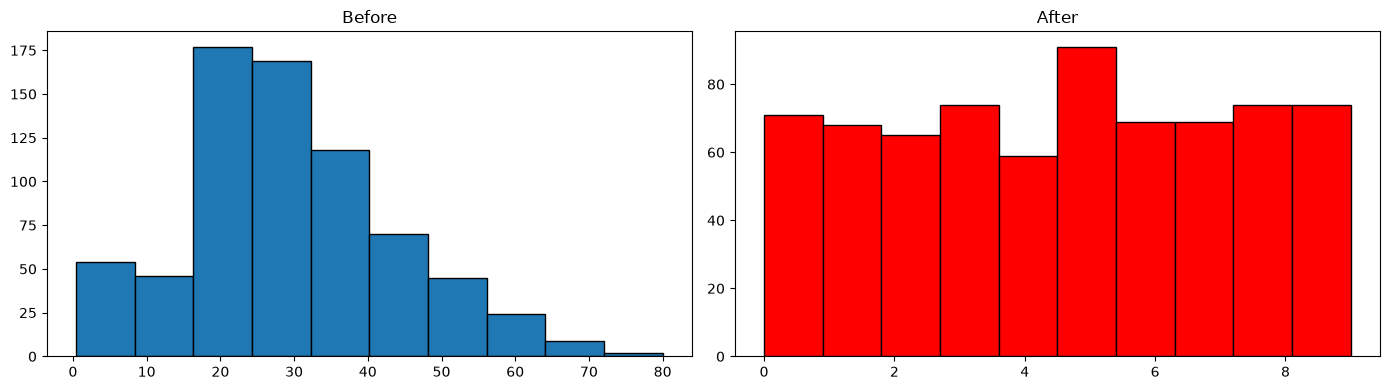

In [42]:
discretize(10,'quantile')

# Binarization  

In [43]:
import numpy as np 
import pandas as pd 


In [44]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score

from sklearn.compose import ColumnTransformer


In [46]:
df = pd.read_csv('train.csv')[['Age','Fare','SibSp','Parch','Survived']]

In [47]:
df.dropna(inplace=True)

In [48]:
df.sample(5)

,Age,Fare,SibSp,Parch,Survived
540,36.0,71.0000,0,2,1
455,29.0,7.8958,0,0,1
730,29.0,211.3375,0,0,1
16,2.0,29.1250,4,1,0
865,42.0,13.0000,0,0,1


In [49]:
df['Family']= df['SibSp']+df['Parch']

In [50]:
df.head()

,Age,Fare,SibSp,Parch,Survived,Family
0,22.0,7.2500,1,0,0,1
1,38.0,71.2833,1,0,1,1
2,26.0,7.9250,0,0,1,0
3,35.0,53.1000,1,0,1,1
4,35.0,8.0500,0,0,0,0


In [51]:
df.drop(columns=['SibSp','Parch'],inplace=True)

In [52]:
df.head()

,Age,Fare,Survived,Family
0,22.0,7.2500,0,1
1,38.0,71.2833,1,1
2,26.0,7.9250,1,0
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


In [53]:
X = df.drop(columns=['Survived'])
y=df['Survived']

In [54]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [56]:
X_train.head()

,Age,Fare,Family
328,31.0,20.5250,2
73,26.0,14.4542,1
253,30.0,16.1000,1
719,33.0,7.7750,0
666,25.0,13.0000,0


In [57]:
# without Binarization
clf =DecisionTreeClassifier()

clf.fit(X_train,y_train)

y_pred = clf.predict(X_test)

accuracy_score(y_test,y_pred)

0.6363636363636364

In [58]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,y,cv=10,scoring='accuracy'))

np.float64(0.6401017214397496)

In [60]:
# Applying Binarization 
from sklearn.preprocessing import Binarizer


In [61]:
trf = ColumnTransformer([
    ('bin',Binarizer(copy=False),['Family'])
],remainder='passthrough')

In [62]:
X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [63]:
pd.DataFrame(X_train_trf,columns=['Family','Age','Fare'])

,Family,Age,Fare
0,1.0,31.0,20.5250
1,1.0,26.0,14.4542
2,1.0,30.0,16.1000
3,0.0,33.0,7.7750
4,0.0,25.0,13.0000
...,...,...,...
566,1.0,46.0,61.1750
567,0.0,25.0,13.0000
568,0.0,41.0,134.5000
569,1.0,33.0,20.5250


In [65]:
clf =DecisionTreeClassifier()

clf.fit(X_train_trf,y_train)

y_pred2 = clf.predict(X_test_trf)

accuracy_score(y_test,y_pred2)

0.6153846153846154

In [67]:
X_trf =trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(),X_trf,y,cv=10,scoring = 'accuracy'))

np.float64(0.6262128325508607)